In [47]:
# importing libraries for data analysis

import pandas as pd
import numpy as np

# importing libraries for data visualization

import matplotlib.pyplot as plt
import seaborn as sns

# importing libraries for machine learning

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.impute import SimpleImputer

# displaying settings
pd.set_option("display.max_columns", None)
print("All libraries imported successfully!")

All libraries imported successfully!


In [48]:
# loading the training dataset

train_data = pd.read_csv("datasets/train.csv")

# loading the testing dataset

test_data = pd.read_csv("datasets/test.csv")

print("Datasets loads successfully!")

Datasets loads successfully!


In [49]:
# displaying the first five rows of training dataset

train_data.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [50]:
# checking the dimension of the dataset

print("Training dataset shape", train_data.shape)

print("Testing dataset shape", test_data.shape)

Training dataset shape (614, 13)
Testing dataset shape (367, 12)


In [51]:
# displaying the information of the training dataset

train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB


In [52]:
# generating statistical summaries

train_data.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [53]:
# checking for missing values in the training dataset

missing_values = train_data.isnull().sum()

print("Missing values in train dataset:")
print(missing_values)

Missing values in train dataset:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64


In [54]:
# calculating the percentage of the missing values

missing_values_percentage = (
    train_data.isnull().sum() / len(train_data)
) * 100

print(missing_values_percentage)



Loan_ID              0.000000
Gender               2.117264
Married              0.488599
Dependents           2.442997
Education            0.000000
Self_Employed        5.211726
ApplicantIncome      0.000000
CoapplicantIncome    0.000000
LoanAmount           3.583062
Loan_Amount_Term     2.280130
Credit_History       8.143322
Property_Area        0.000000
Loan_Status          0.000000
dtype: float64


In [55]:
# checking the missing values in the testing dataset

print("Missing values in testing dataset:")
print(test_data.isnull().sum())

Missing values in testing dataset:
Loan_ID               0
Gender               11
Married               0
Dependents           10
Education             0
Self_Employed        23
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            5
Loan_Amount_Term      6
Credit_History       29
Property_Area         0
dtype: int64


In [56]:
# checking for duplicate rows in the training dataset

print("Duplicate rows:", train_data.duplicated().sum())

Duplicate rows: 0


In [57]:
# checking for duplicate loan IDs

print("Duplicate Loan IDs:", train_data["Loan_ID"].duplicated().sum())

Duplicate Loan IDs: 0


In [58]:
# diplaying unique values in categorical columns

categorical_columns = train_data.select_dtypes(
    include=["object", "str"]
).columns

for column in categorical_columns:
    print(f"\n{column}")
    print(train_data[column].unique())


Loan_ID
<ArrowStringArray>
['LP001002', 'LP001003', 'LP001005', 'LP001006', 'LP001008', 'LP001011',
 'LP001013', 'LP001014', 'LP001018', 'LP001020',
 ...
 'LP002959', 'LP002960', 'LP002961', 'LP002964', 'LP002974', 'LP002978',
 'LP002979', 'LP002983', 'LP002984', 'LP002990']
Length: 614, dtype: str

Gender
<ArrowStringArray>
['Male', 'Female', nan]
Length: 3, dtype: str

Married
<ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str

Dependents
<ArrowStringArray>
['0', '1', '2', '3+', nan]
Length: 5, dtype: str

Education
<ArrowStringArray>
['Graduate', 'Not Graduate']
Length: 2, dtype: str

Self_Employed
<ArrowStringArray>
['No', 'Yes', nan]
Length: 3, dtype: str

Property_Area
<ArrowStringArray>
['Urban', 'Rural', 'Semiurban']
Length: 3, dtype: str

Loan_Status
<ArrowStringArray>
['Y', 'N']
Length: 2, dtype: str


In [59]:
# statistical summary of categorical columns

train_data.describe(include="object")

C:\Users\hp\AppData\Local\Temp\ipykernel_30076\3909399235.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  train_data.describe(include="object")


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,Property_Area,Loan_Status
count,614,601,611,599,614,582,614,614
unique,614,2,2,4,2,2,3,2
top,LP001002,Male,Yes,0,Graduate,No,Semiurban,Y
freq,1,489,398,345,480,500,233,422


In [60]:
# counting loan approval outcomes

print(train_data["Loan_Status"].value_counts())

Loan_Status
Y    422
N    192
Name: count, dtype: int64


In [61]:
# calculating the percentage distribution

loan_status_percentage = (
    train_data["Loan_Status"].value_counts(normalize=True) * 100
)

print(loan_status_percentage)

Loan_Status
Y    68.729642
N    31.270358
Name: proportion, dtype: float64


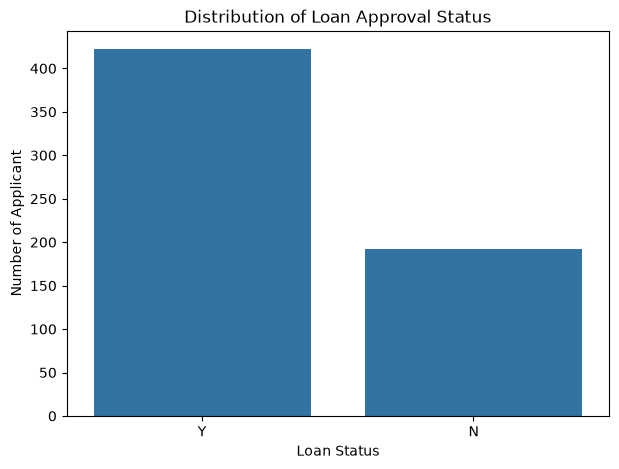

In [62]:
# visualizing loan approval distribution

plt.figure(figsize=(7, 5))

sns.countplot(
    data=train_data,
    x="Loan_Status"
)

plt.title("Distribution of Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicant")

plt.show()

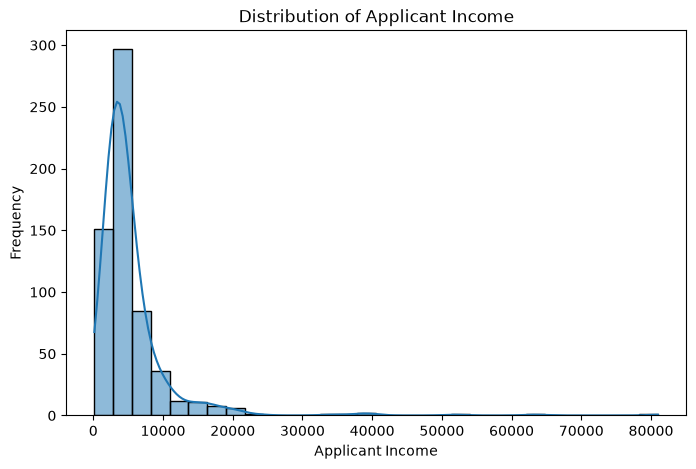

In [63]:
# visualizing applicant income distribution

plt.figure(figsize=(8, 5))

sns.histplot(
    data=train_data,
    x="ApplicantIncome",
    bins=30,
    kde=True
)

plt.title("Distribution of Applicant Income")
plt.xlabel("Applicant Income")
plt.ylabel("Frequency")

plt.show()

In [64]:
# separating the features from the target variable

x = train_data.drop(
    columns=["Loan_ID", "Loan_Status"]
)

y = train_data["Loan_Status"]

# displaying the features and target

print("Features shape:", x.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(x.columns.tolist())

print("\nTarget values:")
print(y.unique())

Features shape: (614, 11)
Target shape: (614,)

Feature columns:
['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Property_Area']

Target values:
<ArrowStringArray>
['Y', 'N']
Length: 2, dtype: str


In [65]:
# converting 3+ to 3 in the dependent column

x["Dependents"] = x["Dependents"].replace("3+", "3")

# converting dependents to numerical values
x["Dependents"] = pd.to_numeric(
    x["Dependents"],
    errors="coerce"
)

print(x["Dependents"].unique())

[ 0.  1.  2.  3. nan]


In [66]:
# converting loan status to numerical values

y = y.map({
    "Y": 1,
    "N": 0
})

print(y.head())

print("\nTarget value counts:")
print(y.value_counts())

0    1
1    0
2    1
3    1
4    1
Name: Loan_Status, dtype: int64

Target value counts:
Loan_Status
1    422
0    192
Name: count, dtype: int64


In [67]:
# identifying numerical features

numerical_features = [
    "Dependents",
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

# identifying categorical features

categorical_features = [
    "Gender",
    "Married",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area"
]

print("Numerical Features:")
print(numerical_features)

print("Categorical Features:")
print(categorical_features)

Numerical Features:
['Dependents', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']
Categorical Features:
['Gender', 'Married', 'Education', 'Self_Employed', 'Credit_History', 'Property_Area']


In [68]:
# splitting the dataset into training and validation sets

x_train, x_val, y_train, y_val = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# displaying the shapes

print("Training features:", x_train.shape)
print("Validation features:", x_val.shape)

print("Training target:", y_train.shape)
print("Validation target:", y_val.shape)

Training features: (491, 11)
Validation features: (123, 11)
Training target: (491,)
Validation target: (123,)


In [69]:
# verifying the training and validation distribution

print("Original target distribution:")
print(y.value_counts(normalize=True).round(3))

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target distribution:")
print(y_val.value_counts(normalize=True).round(3))

Original target distribution:
Loan_Status
1    0.687
0    0.313
Name: proportion, dtype: float64

Training target distribution:
Loan_Status
1    0.686
0    0.314
Name: proportion, dtype: float64

Validation target distribution:
Loan_Status
1    0.691
0    0.309
Name: proportion, dtype: float64


In [70]:
# importing preprocessing tools

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

print("Preprocessing tools imported successfully!")

Preprocessing tools imported successfully!


In [71]:
# creating numerical preprocessing

numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print("Numerical preprocessing pipeline created successfully!")

Numerical preprocessing pipeline created successfully!


In [72]:
# creating the categorical preprocessing pipeline

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

print("Categorical preprocessing pipeline created successfully!")

Categorical preprocessing pipeline created successfully!


In [73]:
# combining numerical and categorical preprocessing

preprocessor = ColumnTransformer(
    transformers=[
        ("numerical", numerical_pipeline, numerical_features),
        ("categorical", categorical_pipeline, categorical_features)

    ]
)

print("Complete preprocessing system created successfully!")

Complete preprocessing system created successfully!


In [74]:
# fitting and transforming the training model

x_train_processed = preprocessor.fit_transform(x_train)

print("Training data preprocessing completed!")
print("Original training shape:", x_train.shape)
print("Processed training shape:", x_train_processed.shape)

Training data preprocessing completed!
Original training shape: (491, 11)
Processed training shape: (491, 18)


In [75]:
# transforming the validation data

x_val_processed = preprocessor.transform(x_val)

print("Validation data preprocessing completed!")
print("Original validation shape:", x_val.shape)
print("Processed validation shape:", x_val_processed.shape)

Validation data preprocessing completed!
Original validation shape: (123, 11)
Processed validation shape: (123, 18)


In [76]:
# checking the processed training data

print("Processed training data:")
print(x_train_processed[:5])

print("\nProcessed validation data:")
print(x_val_processed[:5])

print("\nTraining data contains missing values:",
np.isnan(x_train_processed).any())

print("\nValidation data contains missing values:",
np.isnan(x_val_processed).any())

Processed training data:
[[-0.74858624 -0.352802   -0.56322811 -1.13158849  0.28069139  0.
   1.          1.          0.          1.          0.          1.
   0.          0.          1.          0.          0.          1.        ]
 [ 0.25020681 -0.3433464  -0.56322811 -0.59230932  0.28069139  0.
   1.          0.          1.          1.          0.          1.
   0.          0.          1.          0.          1.          0.        ]
 [ 1.24899986 -0.33947116  0.05040502  0.04075753  0.28069139  0.
   1.          0.          1.          1.          0.          1.
   0.          1.          0.          1.          0.          0.        ]
 [ 0.25020681 -0.44596289 -0.02495343 -0.3930105  -2.48676788  0.
   1.          0.          1.          0.          1.          1.
   0.          1.          0.          1.          0.          0.        ]
 [-0.74858624 -0.45107822  0.23449496  0.04075753  0.28069139  0.
   1.          0.          1.          1.          0.          1.
   0.          

In [77]:
# importing logistic regression

from sklearn.linear_model import LogisticRegression

# importing model evaluation tools

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score
)
print("Logistic regression and evaluation tools imported successfully!")

Logistic regression and evaluation tools imported successfully!


In [78]:
# creating the logistic regression model pipeline

logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

print("Logistic Regression pipeline created successfully")

Logistic Regression pipeline created successfully


In [79]:
# training the logistic regression model

logistic_model.fit(x_train, y_train)

print("Logistic regression model trained successfully!")

Logistic regression model trained successfully!


In [80]:
# predicting loan approval using validation data

y_pred = logistic_model.predict(x_val)

print("predictions:")
print(y_pred[:20])

print("\nActual loan statuses:")
print(y_val.values[:20])

predictions:
[0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 0 0 1]

Actual loan statuses:
[0 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1]


In [81]:
# calculating model accuracy

accuracy = accuracy_score(y_val, y_pred)

print("Logistic Regression Accuracy:", round(accuracy * 100, 2), "%")

Logistic Regression Accuracy: 86.18 %


In [82]:
# calaculating evaluation metrics

precision = precision_score(y_val, y_pred, zero_division=0)

recall = recall_score(y_val, y_pred, zero_division=0)

f1 = f1_score(y_val, y_pred, zero_division=0)

print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1:", round(f1, 4))

Precision: 0.84
Recall: 0.9882
F1: 0.9081


In [83]:
# displaying detailed classification report

print(
    classification_report(
        y_val,
        y_pred,
        target_names=["Rejected", "Approved"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123



In [84]:
# Generating the confusion matrix

cm = confusion_matrix(y_val, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[22 16]
 [ 1 84]]


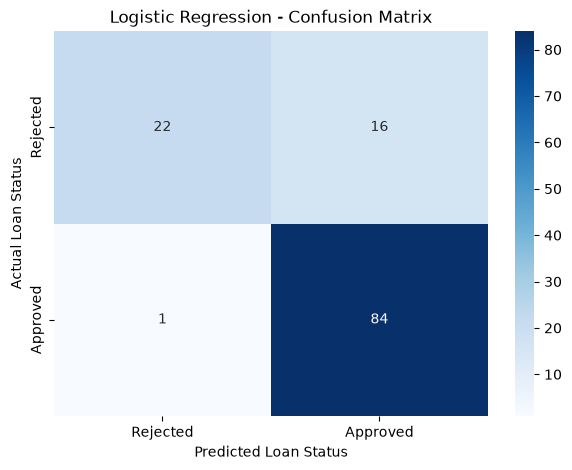

In [85]:
# visualizing confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Loan Status")
plt.ylabel("Actual Loan Status")

plt.show()

In [86]:
# importing the decision tree classifier

from sklearn.tree import DecisionTreeClassifier

print("Decision tree classifier imported successfully!")

Decision tree classifier imported successfully!


In [87]:
# creating decision tree model pipeline

decision_tree_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(random_state=42))
])

print('Decision Tree pipeline created successfully!')

Decision Tree pipeline created successfully!


In [88]:
# training decision tree model

decision_tree_model.fit(x_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


In [89]:
# predicting loan eligibility using decision tree

y_pred_tree = decision_tree_model.predict(x_val)

print("Decision Tree predictions:")
print(y_pred_tree[:20])

print("\nActual loan statuses:")
print(y_val.values[:20])

Decision Tree predictions:
[0 1 1 1 1 0 1 1 0 1 1 1 1 1 0 0 0 0 0 1]

Actual loan statuses:
[0 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1]


In [90]:
# calculating our decision tree accuracy

tree_accuracy = accuracy_score(y_val, y_pred_tree)

print(
    "Decision Tree Accuracy:",
    round(tree_accuracy * 100, 2), "%"
)

Decision Tree Accuracy: 74.8 %


In [91]:
# calculating evaluation metrics

tree_precision = precision_score(
    y_val,
    y_pred_tree,
    zero_division=0
)

tree_recall = recall_score(
    y_val,
    y_pred_tree,
    zero_division=0
)

tree_f1 = f1_score(
    y_val,
    y_pred_tree,
    zero_division=0
)

print("Precision:", round(tree_precision, 4))
print("Recall:", round(tree_recall, 4))
print("F1:", round(tree_f1, 4))

Precision: 0.8214
Recall: 0.8118
F1: 0.8166


In [92]:
# generating decision tree classification report

print(
    classification_report(
        y_val,
        y_pred_tree,
        target_names=["Rejected", "Approved"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    Rejected       0.59      0.61      0.60        38
    Approved       0.82      0.81      0.82        85

    accuracy                           0.75       123
   macro avg       0.71      0.71      0.71       123
weighted avg       0.75      0.75      0.75       123



In [93]:
# generating confusion matrix

cm_tree = confusion_matrix(y_val, y_pred_tree)

print("Decision Tree Confusion Matrix:")
print(cm_tree)

Decision Tree Confusion Matrix:
[[23 15]
 [16 69]]


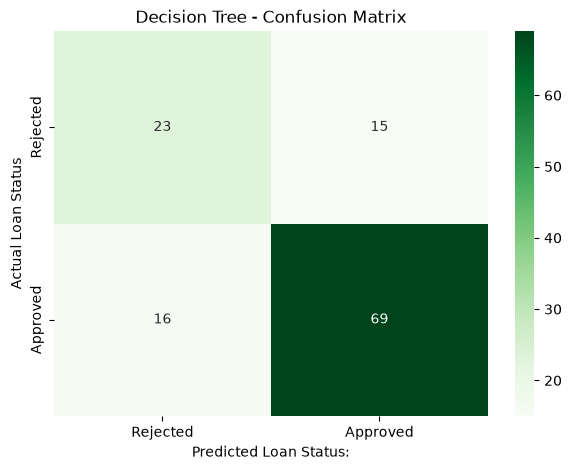

In [94]:
# visualizing decision tree confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_tree,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Loan Status:")
plt.ylabel("Actual Loan Status")

plt.show()


In [95]:
# comparing both classification model

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree"
    ],
    "Accuracy": [
        accuracy,
        tree_accuracy
    ],
    "Precision": [
        precision,
        tree_precision
    ],
    "Recall": [
        recall,
        tree_recall
    ],
    "F1-Score": [
        f1,
        tree_f1
    ]
})

print(model_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.8618     0.8400  0.9882    0.9081
1        Decision Tree    0.7480     0.8214  0.8118    0.8166


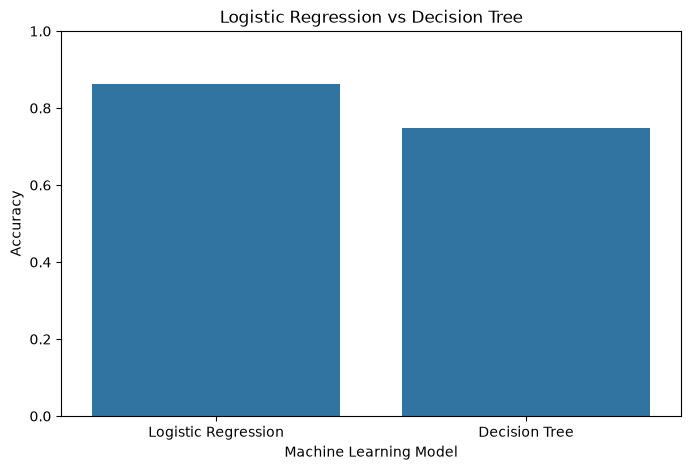

In [96]:
# visualizing the compare model accuracy

plt.figure(figsize=(8, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Logistic Regression vs Decision Tree")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy")

plt.ylim(0, 1)

plt.show()

In [97]:
# importing random forest

from sklearn.ensemble import RandomForestClassifier

print("Random Forest Classifier imported successfully!")

Random Forest Classifier imported successfully!


In [98]:
# Creating Random Forest pipeline

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [99]:
# Training Random Forest

random_forest_model.fit(x_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [100]:
# Predicting loan eligibility

y_pred_forest = random_forest_model.predict(x_val)

print("Random Forest predictions:")
print(y_pred_forest[:20])

print("\nActual loan statuses:")
print(y_val.values[:20])

Random Forest predictions:
[0 1 1 1 1 1 1 1 0 1 1 1 1 1 0 0 0 0 0 1]

Actual loan statuses:
[0 1 1 1 1 0 1 1 1 1 1 1 1 1 0 0 1 0 0 1]


In [101]:
# Calculating evaluation metrics

forest_accuracy = accuracy_score(y_val, y_pred_forest)

forest_precision = precision_score(
    y_val, y_pred_forest, zero_division=0
)

forest_recall = recall_score(
    y_val, y_pred_forest, zero_division=0
)

forest_f1 = f1_score(
    y_val, y_pred_forest, zero_division=0
)

print("Random Forest Evaluation")
print("Accuracy:", round(forest_accuracy, 4))
print("Precision:", round(forest_precision, 4))
print("Recall:", round(forest_recall, 4))
print("F1-Score:", round(forest_f1, 4))

Random Forest Evaluation
Accuracy: 0.813
Precision: 0.8444
Recall: 0.8941
F1-Score: 0.8686


In [102]:
# Classification report

print(classification_report(
    y_val,
    y_pred_forest,
    target_names=["Rejected", "Approved"],
    zero_division=0
))

              precision    recall  f1-score   support

    Rejected       0.73      0.63      0.68        38
    Approved       0.84      0.89      0.87        85

    accuracy                           0.81       123
   macro avg       0.79      0.76      0.77       123
weighted avg       0.81      0.81      0.81       123



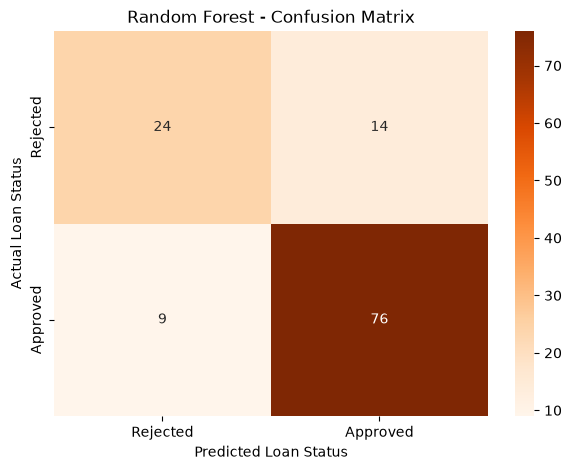

In [103]:
# Confusion matrix

cm_forest = confusion_matrix(y_val, y_pred_forest)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_forest,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Loan Status")
plt.ylabel("Actual Loan Status")

plt.show()

In [104]:
# Comparing all three models

model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy,
        tree_accuracy,
        forest_accuracy
    ],
    "Precision": [
        precision,
        tree_precision,
        forest_precision
    ],
    "Recall": [
        recall,
        tree_recall,
        forest_recall
    ],
    "F1-Score": [
        f1,
        tree_f1,
        forest_f1
    ]
})

print(model_comparison.round(4))

                 Model  Accuracy  Precision  Recall  F1-Score
0  Logistic Regression    0.8618     0.8400  0.9882    0.9081
1        Decision Tree    0.7480     0.8214  0.8118    0.8166
2        Random Forest    0.8130     0.8444  0.8941    0.8686


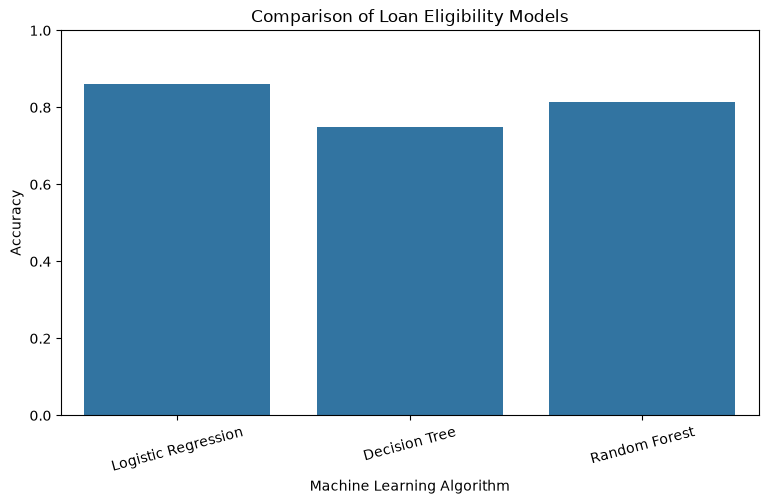

In [105]:
# visualizing their accuracy

plt.figure(figsize=(9, 5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Loan Eligibility Models")
plt.xlabel("Machine Learning Algorithm")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.show()

In [106]:
# Storing the trained models

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

# Identify the model with the highest F1-score

best_model_name = model_comparison.loc[
    model_comparison["F1-Score"].idxmax(),
    "Model"
]

best_model = models[best_model_name]

print("Best model:", best_model_name)

print(
    "Best validation F1-score:",
    round(model_comparison["F1-Score"].max(), 4)
)

Best model: Logistic Regression
Best validation F1-score: 0.9081


In [107]:
# Training the selected model on the complete dataset

best_model.fit(x, y)

print("Best model retrained successfully!")

Best model retrained successfully!


In [108]:
# saving the trained model

import joblib
import os

# Creati saved_models directory

os.makedirs("saved_models", exist_ok=True)

# Saving the final model

model_path = "saved_models/best_loan_eligibility_model.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Saved location:", model_path)

Model saved successfully!
Saved location: saved_models/best_loan_eligibility_model.pkl


In [109]:
import joblib
from pathlib import Path

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier



# checking the training data
print("Checking training data...")

print("x shape:", x.shape)
print("y shape:", y.shape)


# defining the features
numerical_features = [
    "Dependents",
    "ApplicantIncome",
    "CoapplicantIncome",
    "LoanAmount",
    "Loan_Amount_Term"
]

categorical_features = [
    "Gender",
    "Married",
    "Education",
    "Self_Employed",
    "Credit_History",
    "Property_Area"
]


# creating preprocessing pipeline

def create_preprocessor():

    numerical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ])

    return preprocessor


# defining the three model

models = {

    "Logistic Regression": LogisticRegression(
        max_iter=1000
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )

}

# creating the model directory

MODEL_DIR = Path("saved_models")
MODEL_DIR.mkdir(exist_ok=True)


# training and saving all three model

for model_name, classifier in models.items():

    pipeline = Pipeline([
        ("preprocessor", create_preprocessor()),
        ("classifier", classifier)
    ])

    pipeline.fit(x, y)

    filename = (
        model_name.lower().replace(" ", "_") + ".pkl"
    )

    model_path = MODEL_DIR / filename

    joblib.dump(pipeline, model_path)

    print(f"{model_name} trained and saved successfully!")


# confirming saved models

print("\nALL THREE MODELS SAVED SUCCESSFULLY!")

print("\nSaved model files:")

for file in MODEL_DIR.glob("*.pkl"):
    print(file.name)

Checking training data...
x shape: (614, 11)
y shape: (614,)
Logistic Regression trained and saved successfully!
Decision Tree trained and saved successfully!
Random Forest trained and saved successfully!

ALL THREE MODELS SAVED SUCCESSFULLY!

Saved model files:
best_loan_eligibility_model.pkl
decision_tree.pkl
logistic_regression.pkl
random_forest.pkl


In [112]:
# Preparing Kaggle test dataset

test_features = test_data.drop(columns=["Loan_ID"]).copy()

# Converting Dependents into numerical values

test_features["Dependents"] = (
    test_features["Dependents"].replace("3+", "3")
)

test_features["Dependents"] = pd.to_numeric(
    test_features["Dependents"],
    errors="coerce"
)

print("Test dataset prepared successfully!")

print("Test features shape:", test_features.shape)

Test dataset prepared successfully!
Test features shape: (367, 11)


In [113]:
# Predicting loan eligibility

test_predictions = best_model.predict(test_features)

print("Loan eligibility predictions:")
print(test_predictions[:20])

Loan eligibility predictions:
[1 1 1 1 1 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1]


In [114]:
# Convering predictions into Y and N

loan_status_predictions = pd.Series(
    test_predictions
).map({
    1: "Y",
    0: "N"
})

print(loan_status_predictions.head(20))

0     Y
1     Y
2     Y
3     Y
4     Y
5     Y
6     Y
7     N
8     Y
9     Y
10    Y
11    Y
12    Y
13    N
14    Y
15    Y
16    Y
17    Y
18    Y
19    Y
dtype: str


In [115]:
# Creating prediction submission file

submission = pd.DataFrame({
    "Loan_ID": test_data["Loan_ID"],
    "Loan_Status": loan_status_predictions
})

# Saving predictions

submission.to_csv(
    "loan_eligibility_predictions.csv",
    index=False
)

print("Prediction file created successfully!")

print(submission.head())

Prediction file created successfully!
    Loan_ID Loan_Status
0  LP001015           Y
1  LP001022           Y
2  LP001031           Y
3  LP001035           Y
4  LP001051           Y
